In [66]:
import os
from cryoquake import stream_handling as sh
from cryoquake import data_objects as do
from cryoquake import spatial_analysis as sa
from obspy.core.inventory import inventory
from obspy.core import Stream, Trace, read, UTCDateTime
import pandas as pd
from scipy.signal import correlate
import numpy as np
from scipy.cluster import hierarchy
from scipy.spatial import distance
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
#import fastcluster as fc
from plotly_resampler import FigureWidgetResampler
import plotly.graph_objects as go
import xarray as xr
from matplotlib.patches import Rectangle
from matplotlib.dates import DateFormatter, DayLocator, HourLocator
from scipy.stats import chi2
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap, Normalize

import pyproj
proj_wgs84 = pyproj.Proj(init="epsg:4326")
proj_epsg3031 = pyproj.Proj(init="epsg:3031")

import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import cartopy as ctp

from shapely.ops import transform as shp_transform

/Users/jaredmagyar/miniconda3/envs/seismo_analysis/lib/python3.11/site-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
/Users/jaredmagyar/miniconda3/envs/seismo_analysis/lib/python3.11/site-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)


In [67]:

wgs84 = ccrs.PlateCarree()
stereo = ccrs.epsg(3031)
map_proj = ccrs.SouthPolarStereo()

In [68]:
def cmap_bedmachine():
  colors = [
    (17/256, 29/256, 57/256), # Dark blue
    (59/256, 89/256, 130/256), # Navy blue
    (102/256, 172/256, 222/256), # Baby blue
    (255/256, 255/256, 255/256), # White
    (58/256, 97/256, 39/256), # Dark green
    (93/256, 156/256, 63/256), # Green
    (195/256, 180/256, 79/256), # Yellow
    (107/256, 82/256, 0), # Brown
    (52/256 ,37/256, 0) # Dark brown
  ]
  values = [-3000, -1000, -500, 0, 1, 500, 1000, 1500, 3000]
  norm = plt.Normalize(min(values), max(values))
  cmapping = list(zip(norm(values), colors))
  custom_cmap = LinearSegmentedColormap.from_list(name = 'BedMachine', colors = cmapping)
  return custom_cmap


vel_cmap = LinearSegmentedColormap.from_list('velocity', (
    # Edit this gradient at https://eltos.github.io/gradient/#velocity=0:FFFFFF-10:4EACE0-20:A6A8A6-40:DBCC65-70:EC1616-100:1B0001
    (0.000, (1.000, 1.000, 1.000)),
    (0.100, (0.306, 0.675, 0.878)),
    (0.200, (0.651, 0.659, 0.651)),
    (0.400, (0.859, 0.800, 0.396)),
    (0.700, (0.925, 0.086, 0.086)),
    (1.000, (0.106, 0.000, 0.004))))

In [6]:
t1 = sh.UTCDateTime(2018,12,24)
t2 = sh.UTCDateTime(2019,1,30)


chunk = do.SeismicChunk(t1,t2)

root = Path.cwd()
w_path = root / "waveforms"
stack_path = root / "stacked_waveforms"
s_path = root / "stations"
m_path = root / "misfit"
c_path = root / "catalogues" / "classic_high_threshold"



inv_files = os.listdir(s_path)

inv = inventory.Inventory()

for file in inv_files:
    temp_path = os.path.join(s_path,file)
    inv += inventory.read_inventory(temp_path,level='response',format='STATIONXML')

inv = inv.select(station='TI?A',channel='CH?')

temp_cat = do.EventCatalogue(t1,t2,c_path,templates=True)
groups = temp_cat.group_split()

In [53]:
directory = '/Users/jaredmagyar/Documents/MappingProducts/' #! replace with path to bed topography netcdf file.
bedmap3_file = directory + 'bedmap3.nc' #! replace with name of bed topography file
bedmap3 = xr.open_dataset(bedmap3_file, engine="netcdf4")
grounding_zone = directory + 'Antarctic_GZ_2018_v01.0.shp'
hydrology_file = directory + 'hydrology_outputs_ll.nc'
hydrology_data = xr.open_dataset(hydrology_file, engine="netcdf4")


xmin = 2.2615e6
xmax = 2.2735e6
ymin = -1.0060e6
ymax = -0.9940e6

resolution = 25 #m

xlin = np.mgrid[xmin:xmax:resolution]
ylin = np.mgrid[ymin:ymax:resolution]


bed_grid = xr.Dataset(coords=dict(x=("x", xlin),y=("y", ylin)))
bedmap_interp = bedmap3.interp_like(bed_grid)
hydro_interp = hydrology_data.interp_like(bed_grid)
bed_grid = bed_grid.assign(dict(bed_topography = bedmap_interp.bed_topography,bed_uncertainty = bedmap_interp.bed_uncertainty,effective_pressure=hydro_interp.effective_pressure))

In [54]:
grounding_zone_data = shpreader.Reader(grounding_zone)

groundingline_file2 = directory + 'InSAR_GL_Antarctica_v02.shp'
coastline_file = directory + 'Coastline_Antarctica_v02.shp'
groundingline_data2 = shpreader.Reader(groundingline_file2)
coastline_data = shpreader.Reader(coastline_file)


up = []
dn = []
isl = []
for record in grounding_zone_data.records():
    if (record.attributes['Boundary'] == 'Up') & (record.attributes['Type'] == 'Ice Sheet'):
        up.append(record)
    if (record.attributes['Boundary'] == 'Dn') & (record.attributes['Type'] == 'Ice Sheet'):
        dn.append(record)
    if ((record.attributes['Type'] == 'Island') | (record.attributes['Type'] == 'EIR')):
        isl.append(record)

from pyproj import Transformer

to_wgs84 = Transformer.from_crs("EPSG:3031", "EPSG:4326", always_xy=True).transform
to_epsg3031 = Transformer.from_crs("EPSG:4326","EPSG:3031", always_xy=True).transform

def reproject_geom(geom):
    """Reproject a shapely geometry from EPSG:3031 to EPSG:4326."""
    return shp_transform(to_wgs84, geom)

def reverse_reproject_geom(geom):
    """Reproject a shapely geometry from EPSG:3031 to EPSG:4326."""
    return shp_transform(to_epsg3031, geom)

up_ll = [reproject_geom(rec.geometry) for rec in up]
dn_ll = [reproject_geom(rec.geometry) for rec in dn]
isl_ll = [reproject_geom(rec.geometry) for rec in isl]

up_xy = [rec.geometry for rec in up]

In [55]:
bedscan = sa.BedScanner(inv,bed_grid)

/Users/jaredmagyar/miniconda3/envs/seismo_analysis/lib/python3.11/site-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
/Users/jaredmagyar/miniconda3/envs/seismo_analysis/lib/python3.11/site-packages/pyproj/crs/crs.py:143: FutureWarning: '+init=<authority>:<code>' syntax is deprecated. '<authority>:<code>' is the preferred initialization method. When making the change, be mindful of axis order changes: https://pyproj4.github.io/pyproj/stable/gotchas.html#axis-order-changes-in-proj-6
  in_crs_string = _prepare_from_proj_string(in_crs_string)
/Users/jaredmagyar/Documents/icequakecode/cryoquake/src/cryoquake/spatial_analysis.py:1217: FutureWarning: This function is deprecated. See: https

No misfit surface for group...
No misfit surface for group...
No misfit surface for group...
No misfit surface for group...
No misfit surface for group...


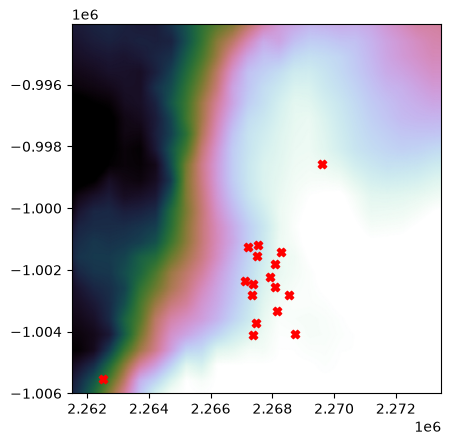

In [56]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.set_aspect('equal')
ax.pcolormesh(xlin,ylin,bed_grid.effective_pressure.T,cmap='cubehelix_r',vmin=0,vmax=2e6,shading='gouraud')

for clust_num in groups.keys():
    try:
        gamma_xr = xr.load_dataset(os.path.join(m_path,'misfit_surface_'+str(clust_num)+'.nc'))
    except FileNotFoundError:
        print('No misfit surface for group...')
        continue

    x0 = gamma_xr.x0
    y0 = gamma_xr.y0

    ax.scatter(x0,y0,color='red',marker='X')

for i, sta_name in enumerate(bedscan.sta_lst):

    sta_x = bedscan.sta_xy[i,0]
    sta_y = bedscan.sta_xy[i,1]

    if (((sta_x <= xlin[-1]) & (sta_x >= xlin[0])) & ((sta_y <= ylin[-1]) & (sta_y >= ylin[0]))):
        ax.scatter(sta_x,sta_y,marker='^',color='red',s=50)
        ax.annotate(sta_name,(sta_x,sta_y),c='white',weight='bold',zorder=5,size=10)


/var/folders/1p/l225gv7d2djg7qs1mf5c5h6c0000gp/T/ipykernel_28897/2825209742.py:171: MatplotlibDeprecationWarning: Since Matplotlib 3.10 indicate_inset_[zoom] returns a single InsetIndicator artist with a rectangle property and a connectors property.  From 3.12 it will no longer be possible to unpack the return value into two elements.
  _, inset_indicator = inset_ax.indicate_inset_zoom(ne_ax, edgecolor = 'maroon',alpha=1,linewidth=2,zorder=25) # indicate on main axes the inset axes


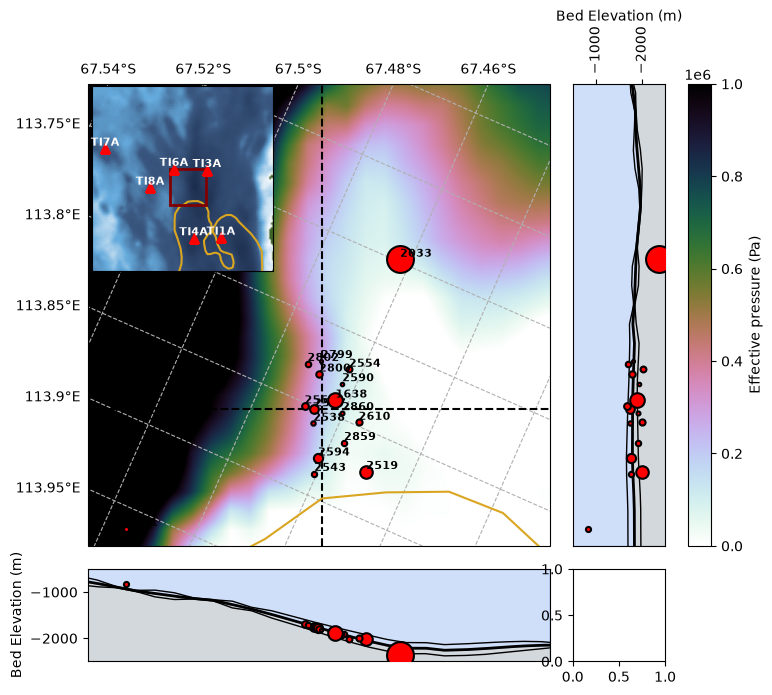

In [76]:
fig = plt.figure(figsize=(6,6))

ne_ax = fig.add_subplot(111,projection = ccrs.SouthPolarStereo())
#ne_ax = fig.add_subplot(111,projection = stereo)
ez_ax = ne_ax.inset_axes(bounds = [0.0,-0.25,1,0.2],transform=ne_ax.transAxes,sharex=ne_ax)
nz_ax = ne_ax.inset_axes(bounds = [1.05,0,0.2,1],transform=ne_ax.transAxes,sharey=ne_ax)
dot_ax = ne_ax.inset_axes(bounds = [1.05,-0.25,0.2,0.2],transform=ne_ax.transAxes)

gl = ne_ax.gridlines(crs=wgs84, draw_labels = {'top':'y','left':'x'}, linestyle = '--',x_inline=False,y_inline=False,rotate_labels=False)

ne_ax.add_geometries(up_xy, crs=ccrs.epsg(3031), facecolor="none", edgecolor="goldenrod", linewidth=1.5,zorder=20)

ep = bed_grid.effective_pressure.values
ep[ep<=0.0] = -2e5

pc_ep = ne_ax.pcolormesh(xlin,ylin,ep.T,cmap='cubehelix_r',vmin=0,vmax=1e6,shading='gouraud',transform=stereo,rasterized=True)

skip = 50

X, Y = np.meshgrid(xlin[::skip], ylin[::skip])
XYT = ne_ax.projection.transform_points(stereo,X,Y)
X1 = XYT[:,:,0]
Y1 = XYT[:,:,1]

#U = bed_grid.velX.values[::skip, ::skip]
#V = bed_grid.velY.values[::skip, ::skip]

#mag = np.sqrt(U**2 + V**2)

# Uhat = U / mag
# Vhat = V / mag

# Uhat[mag <= 50] = np.nan
# Vhat[mag <= 50] = np.nan


# ne_ax.quiver(X1,Y1,Uhat,Vhat,mag,cmap=vel_cmap,scale=40,headwidth=6,headlength=8,headaxislength=8,edgecolor='black',linewidth=0.7,norm=Normalize(vmin=0,vmax=1000))

ne_ax.set_aspect('equal')

x_tot = 0.0
y_tot = 0.0

n = 0

for clust_num in groups.keys():

    try:
        gamma_xr = xr.load_dataset(os.path.join(m_path,'misfit_surface_'+str(clust_num)+'.nc'))
        n += 1
    except FileNotFoundError:
        continue

    xlin = gamma_xr.x.to_numpy()
    ylin = gamma_xr.y.to_numpy()
    gamma = gamma_xr.gamma.to_numpy()

    x_ind, y_ind = np.unravel_index(np.argmin(gamma),gamma.shape)
    x_loc = xlin[x_ind]
    y_loc = ylin[y_ind]

    z_loc = bed_grid.bed_topography.isel(x=x_ind,y=y_ind)

    x_tot += x_loc
    y_tot += y_loc

    size = gamma_xr.N / 5

    ne_ax.scatter(x_loc,y_loc,marker='o',s=size,zorder=5,color='red',edgecolors='black',linewidths=1.5,transform=stereo)
    ne_ax.annotate(str(clust_num),(x_loc,y_loc),c='black',weight='bold',zorder=5,size=8,transform=stereo,va='bottom')


    x_proj = ccrs.SouthPolarStereo().transform_points(ccrs.epsg(3031),xlin,np.full_like(xlin,y_loc))[:,0]
    y_proj = ccrs.SouthPolarStereo().transform_points(ccrs.epsg(3031),ylin,np.full_like(ylin,x_loc))[:,0]

    ez_ax.scatter(x_proj[x_ind],z_loc,marker='o',s=size,zorder=5,color='red',edgecolors='black',linewidths=1.5)
    nz_ax.scatter(z_loc,y_proj[y_ind],marker='o',s=size,zorder=5,color='red',edgecolors='black',linewidths=1.5)


mean_x = x_tot / n
mean_y = y_tot / n

for i, sta_name in enumerate(bedscan.sta_lst):

    sta_x = bedscan.sta_xy[i,0]
    sta_y = bedscan.sta_xy[i,1]

    if (((sta_x <= xlin[-1]) & (sta_x >= xlin[0])) & ((sta_y <= ylin[-1]) & (sta_y >= ylin[0]))):
        ne_ax.scatter(sta_x,sta_y,marker='^',color='red',s=50,transform=stereo)
        ne_ax.annotate(sta_name,(sta_x,sta_y),c='white',weight='bold',zorder=5,size=10,transform=stereo,va='bottom')



ne_ax.set_xlim((x_proj[0],x_proj[-1]))
ne_ax.set_ylim((y_proj[0],y_proj[-1]))

bed_x = bed_grid.interp(y=mean_y).bed_topography.values
bed_dx = bed_grid.interp(y=mean_y).bed_uncertainty.values

ez_ax.fill_between(x_proj,-2500,bed_x,color='slategrey',alpha=0.3)
ez_ax.fill_between(x_proj,bed_x,-500,color='cornflowerblue',alpha=0.3)

ez_ax.plot(x_proj,bed_x,lw=2,color='black')
ez_ax.plot(x_proj,bed_x + bed_dx,lw=1,color='black')
ez_ax.plot(x_proj,bed_x - bed_dx,lw=1,color='black')
ez_ax.set_yticks([-1000,-2000])
ez_ax.set_ylim(-2500,-500)


bed_y = bed_grid.interp(x=mean_x).bed_topography.values
bed_dy = bed_grid.interp(x=mean_x).bed_uncertainty.values

nz_ax.fill_betweenx(y_proj,bed_y,-2500,color='slategrey',alpha=0.3)
nz_ax.fill_betweenx(y_proj,-500,bed_y,color='cornflowerblue',alpha=0.3)

nz_ax.plot(bed_y,y_proj,lw=2,color='black')
nz_ax.plot(bed_y + bed_dy,y_proj,lw=1,color='black')
nz_ax.plot(bed_y - bed_dy,y_proj,lw=1,color='black')
nz_ax.set_xticks([-1000,-2000])
nz_ax.set_xlim(-500,-2500)

ne_ax.hlines(mean_y,xmin=xlin[0],xmax=xlin[-1],color='black',ls='--',transform=stereo)
ne_ax.vlines(mean_x,ymin=ylin[0],ymax=ylin[-1],color='black',ls='--',transform=stereo)

ez_ax.set_xticks([])
nz_ax.set_yticks([])

nz_ax.tick_params(axis='x', labelrotation=90)


nz_ax.xaxis.set_ticks_position('top')

ez_ax.set_ylabel('Bed Elevation (m)')
nz_ax.set_xlabel('Bed Elevation (m)')

nz_ax.xaxis.set_label_position('top')

cb_ax = ne_ax.inset_axes(bounds = [1.3,0,0.05,1],transform=ne_ax.transAxes)
clb = fig.colorbar(pc_ep, cax = cb_ax)
clb.set_label('Effective pressure (Pa)')

# cb_ax2 = ne_ax.inset_axes(bounds = [0,-0.355,1,0.05],transform=ne_ax.transAxes)
# clb = fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0,1000),cmap=vel_cmap), cax = cb_ax2,orientation='horizontal')
# clb.set_label('Ice velocity (m/yr)')


# scalebar = ScaleBar(0.001, "km", length_fraction=0.25,border_pad=0.25,fixed_value=2)
# ne_ax.add_artist(scalebar)

# dot_c = cmap(cb_map(np.array([0,0.5,1]),0,1))
# dot_ax.scatter([0,0,0],[1,2,3],c=dot_c,marker='o',s=150,zorder=5,edgecolors='black',linewidths=1.5)

# dot_ax.set_ylim(0,4)
# dot_ax.set_xlim(-0.5,4)
# dot_ax.set_axis_off()

# dot_ax.annotate('Strong Tidal Anomaly',xy=(1,3),ha='left',va='center',fontsize=9)
# dot_ax.annotate('Weak Tidal Anomaly',xy=(1,2),ha='left',va='center',fontsize=9)
# dot_ax.annotate('No Tidal Anomaly',xy=(1,1),ha='left',va='center',fontsize=9)

inset_ax = ne_ax.inset_axes(bounds = [0.005, 1-0.4-0.005, 0.4, 0.4], transform = ne_ax.transAxes, projection = ccrs.SouthPolarStereo(),zorder=50)
inset_ax.set_extent([113.2, 114.3, -67.7, -67.3],crs=wgs84)


inset_grid = xr.Dataset(coords=dict(x=("x", np.mgrid[2.2e6:2.3e6:500]),y=("y", np.mgrid[-1.1e6:-0.95e6:500])))
bedmap_interp = bedmap3.interp_like(inset_grid)
inset_grid = inset_grid.assign(dict(bed_topography = bedmap_interp.bed_topography))

inset_ax.pcolormesh(inset_grid.x,inset_grid.y,inset_grid.bed_topography,shading='gouraud',rasterized=True, transform=stereo,cmap = cmap_bedmachine(),vmin=-3000,vmax=3000)

_, inset_indicator = inset_ax.indicate_inset_zoom(ne_ax, edgecolor = 'maroon',alpha=1,linewidth=2,zorder=25) # indicate on main axes the inset axes

for connector in inset_indicator:
    connector.set_visible(False)


inset_ax.add_geometries(up_xy, crs=ccrs.epsg(3031), facecolor="none", edgecolor="goldenrod", linewidth=1.5,zorder=20)
inset_ax.add_geometries(dn_ll, crs=ccrs.epsg(3031), facecolor="none", edgecolor="palegoldenrod", linewidth=1.5, zorder=20)
inset_ax.add_geometries(isl_ll, crs=ccrs.epsg(3031), facecolor="none", edgecolor="white", linewidth=1.5, zorder=20)


for i, sta_name in enumerate(bedscan.sta_lst):

    sta_x = bedscan.sta_xy[i,0]
    sta_y = bedscan.sta_xy[i,1]

    inset_ax.scatter(sta_x,sta_y,marker='^',color='red',s=50,transform=stereo,zorder=30)
    inset_ax.annotate(sta_name,(sta_x,sta_y),c='white',weight='bold',zorder=30,size=8,transform=stereo,ha='center',va='bottom')


#scalebar = ScaleBar(0.001, "km", length_fraction=0.25,border_pad=0.25,fixed_value=20)
#inset_ax.add_artist(scalebar)
